In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv('Zomato Restaurant Dataset.csv')

print(df.head())

   Restaurant ID         Restaurant Name  Country Code              City  \
0        6317637        Le Petit Souffle           162       Makati City   
1        6304287        Izakaya Kikufuji           162       Makati City   
2        6300002  Heat - Edsa Shangri-La           162  Mandaluyong City   
3        6318506                    Ooma           162  Mandaluyong City   
4        6314302             Sambo Kojin           162  Mandaluyong City   

                                             Address  \
0  Third Floor, Century City Mall, Kalayaan Avenu...   
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...   
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...   
3  Third Floor, Mega Fashion Hall, SM Megamall, O...   
4  Third Floor, Mega Atrium, SM Megamall, Ortigas...   

                                     Locality  \
0   Century City Mall, Poblacion, Makati City   
1  Little Tokyo, Legaspi Village, Makati City   
2  Edsa Shangri-La, Ortigas, Mandaluyong City   
3      SM 

In [3]:
duplicados = df.duplicated().sum()
print(f'Filas duplicadas eliminadas: {duplicados}')
df = df.drop_duplicates()

df['Cuisines'] = df['Cuisines'].fillna('Sin Clasificar')

print(f'Total de valores nulos restantes: {df.isnull().sum().sum()}')

Filas duplicadas eliminadas: 0
Total de valores nulos restantes: 0


In [4]:
total_restaurantes = df['Restaurant ID'].nunique()
total_votos = df['Votes'].sum()
promedio_calificacion = df['Aggregate rating'].mean()
promedio_costo = df['Average Cost for two'].mean()
pct_online_delivery = (df['Has Online delivery'] == 'Yes').mean() * 100
pct_table_booking = (df['Has Table booking'] == 'Yes').mean() * 100

print('=== INDICADORES CLAVE DE RENDIMIENTO (KPIs) ===')
print(f'1. Total de Restaurantes Analizados: {total_restaurantes:,}')
print(f'2. Total de Votos Registrados: {total_votos:,}')
print(f'3. Calificación Promedio Global: {promedio_calificacion:.2f} / 5.0')
print(f'4. Costo Promedio para Dos Personas: {promedio_costo:.2f}')
print(
    '5. Porcentaje con Servicio a Domicilio (Delivery):'
    f' {pct_online_delivery:.1f}%'
)
print(
    f'6. Porcentaje con Reserva de Mesa (Table Booking): {pct_table_booking:.1f}%'
)

=== INDICADORES CLAVE DE RENDIMIENTO (KPIs) ===
1. Total de Restaurantes Analizados: 9,551
2. Total de Votos Registrados: 1,498,645
3. Calificación Promedio Global: 2.67 / 5.0
4. Costo Promedio para Dos Personas: 1199.21
5. Porcentaje con Servicio a Domicilio (Delivery): 25.7%
6. Porcentaje con Reserva de Mesa (Table Booking): 12.1%


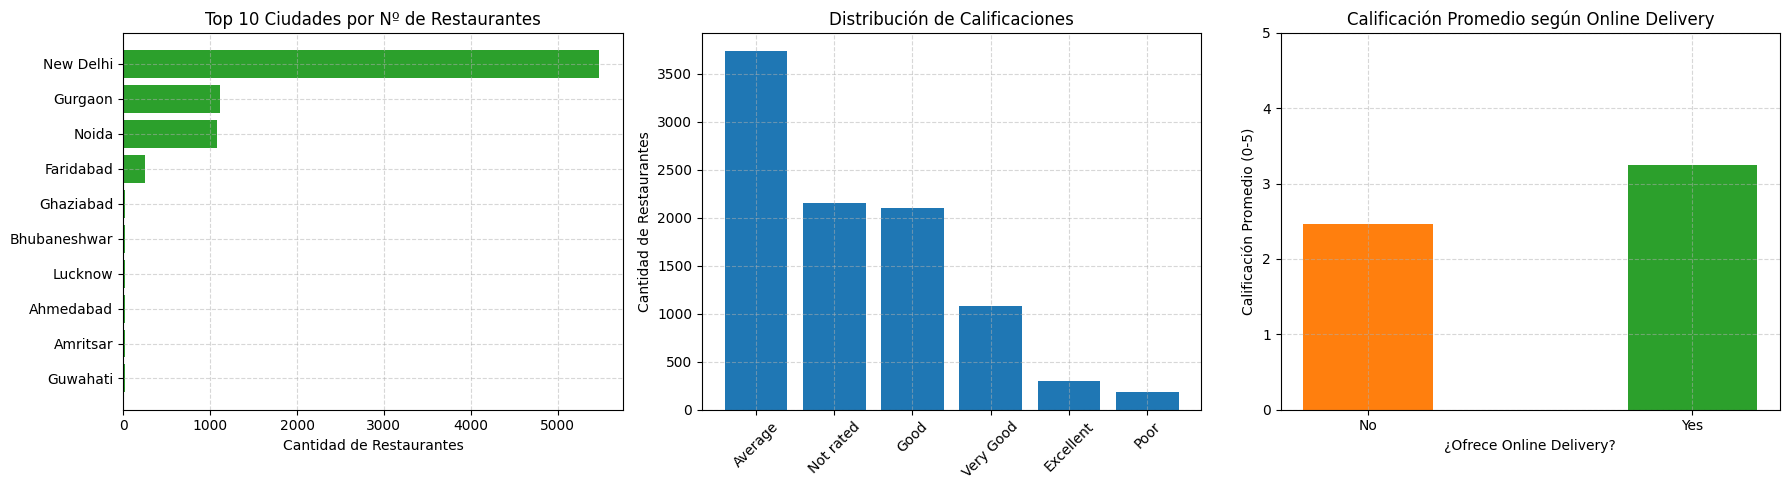

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

top_cities = df['City'].value_counts().head(10)
axes[0].barh(top_cities.index[::-1], top_cities.values[::-1], color='#2ca02c')
axes[0].set_title('Top 10 Ciudades por Nº de Restaurantes')
axes[0].set_xlabel('Cantidad de Restaurantes')
axes[0].grid(True, linestyle='--', alpha=0.5)

rating_counts = df['Rating text'].value_counts()
axes[1].bar(rating_counts.index, rating_counts.values, color='#1f77b4')
axes[1].set_title('Distribución de Calificaciones')
axes[1].set_ylabel('Cantidad de Restaurantes')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, linestyle='--', alpha=0.5)

delivery_rating = df.groupby('Has Online delivery')['Aggregate rating'].mean()
axes[2].bar(
    delivery_rating.index,
    delivery_rating.values,
    color=['#ff7f0e', '#2ca02c'],
    width=0.4,
)
axes[2].set_title('Calificación Promedio según Online Delivery')
axes[2].set_xlabel('¿Ofrece Online Delivery?')
axes[2].set_ylabel('Calificación Promedio (0-5)')
axes[2].set_ylim(0, 5)
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()